<a href="https://colab.research.google.com/github/Mohamed-ktari/advanced-signal/blob/main/LAB2_Advanced_Signal_Mohamed_ktari.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [59]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import lfilter,firwin,fftconvolve
import librosa
import scipy.io as sio
import IPython.display as ipd

In [2]:
N = 1000
np.random.seed(0)
x = np.random.randn(N)
h = np.array([1, 0.5, 0.1, -0.2])
d = lfilter(h, [1], x)

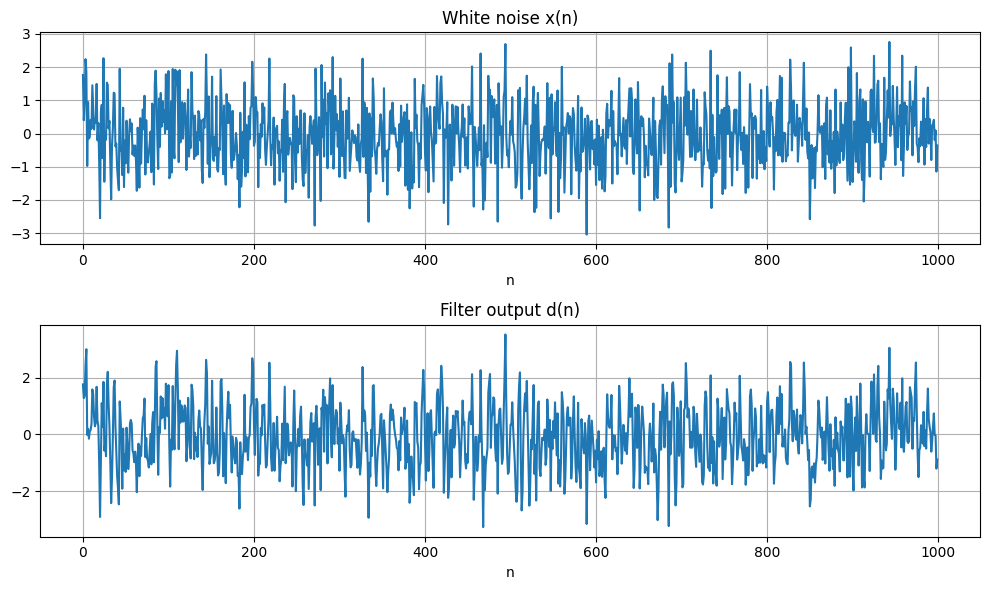

In [3]:
plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.plot(x)
plt.title("White noise x(n)")
plt.xlabel("n")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(d)
plt.title("Filter output d(n)")
plt.xlabel("n")
plt.grid(True)

plt.tight_layout()
plt.show()

In [17]:

def algoLMS(x, d, M, mu):
    x = np.asarray(x, dtype=float)
    d = np.asarray(d, dtype=float)
    N = len(x)

    w = np.zeros(M)
    W = np.zeros((N, M))
    y = np.zeros(N)
    e = np.zeros(N)


    x_pad = np.concatenate((np.zeros(M - 1), x))

    for n in range(N):
        xn = x_pad[n:n + M][::-1]
        y[n] = w @ xn
        e[n] = d[n] - y[n]
        w = w + mu * e[n] * xn
        W[n, :] = w

    return W, y, e

In [26]:

M = 4
mu = 0.01
W, y, e= algoLMS(x, d, M, mu)

w_final = W[-1]
print("True h      :", h)
print("Estimated w :", np.round(w_final, 4))
print("Coefficient error ||w - h||² :", np.sum((w_final - h)**2))

True h      : [ 1.   0.5  0.1 -0.2]
Estimated w : [ 0.9999  0.5     0.1    -0.2   ]
Coefficient error ||w - h||² : 6.347134669280719e-09


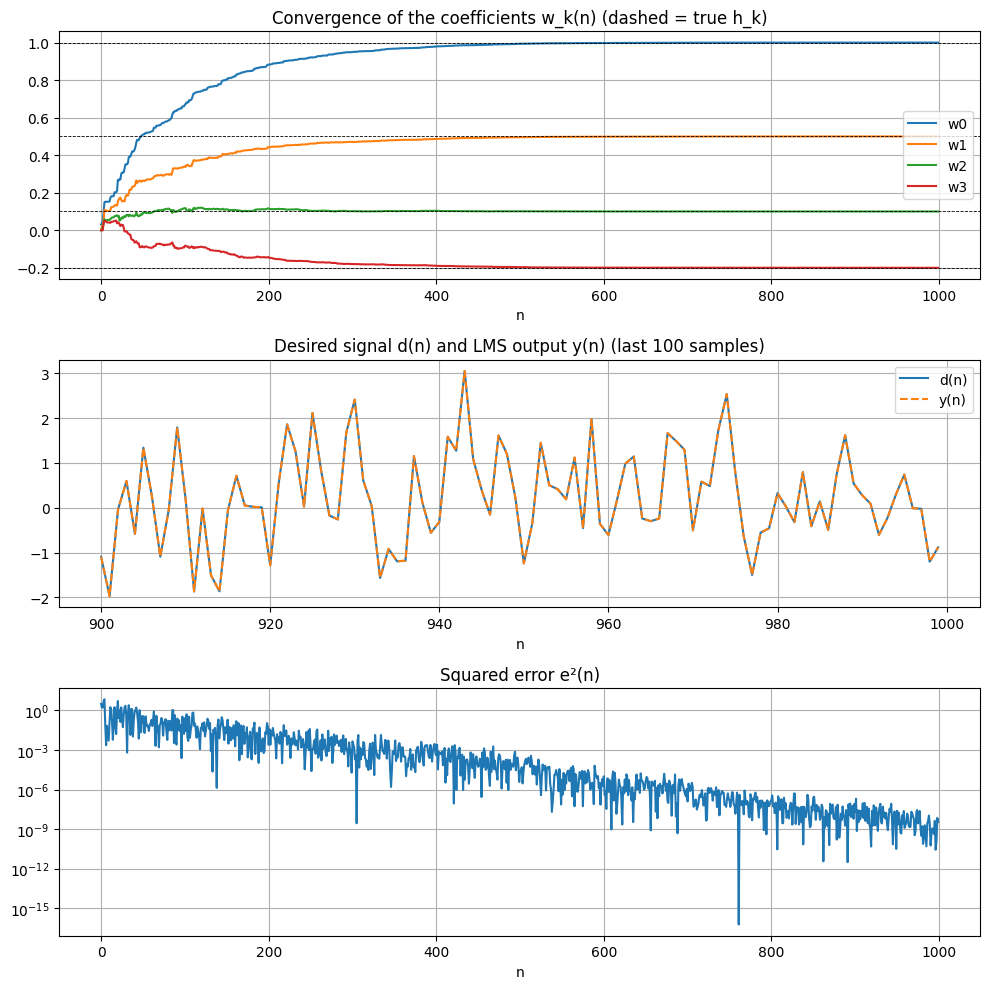

In [19]:
#  Plots
fig, ax = plt.subplots(3, 1, figsize=(10, 10))

# the coefficients
ax[0].plot(W)
for k, hk in enumerate(h):
    ax[0].axhline(hk, color='k', linestyle='--', linewidth=0.6)
ax[0].set_title("Convergence of the coefficients w_k(n) (dashed = true h_k)")
ax[0].legend([f"w{k}" for k in range(M)], loc="right")
ax[0].set_xlabel("n"); ax[0].grid(True)

# Desired signal vs. filter output
sl = slice(N - 100, N)
ax[1].plot(np.arange(N)[sl], d[sl], label="d(n)")
ax[1].plot(np.arange(N)[sl], y[sl], '--', label="y(n)")
ax[1].set_title("Desired signal d(n) and LMS output y(n) (last 100 samples)")
ax[1].legend(); ax[1].set_xlabel("n"); ax[1].grid(True)

# Squared error
ax[2].semilogy(e**2)
ax[2].set_title("Squared error e²(n)")
ax[2].set_xlabel("n"); ax[2].grid(True)

plt.tight_layout()
plt.show()

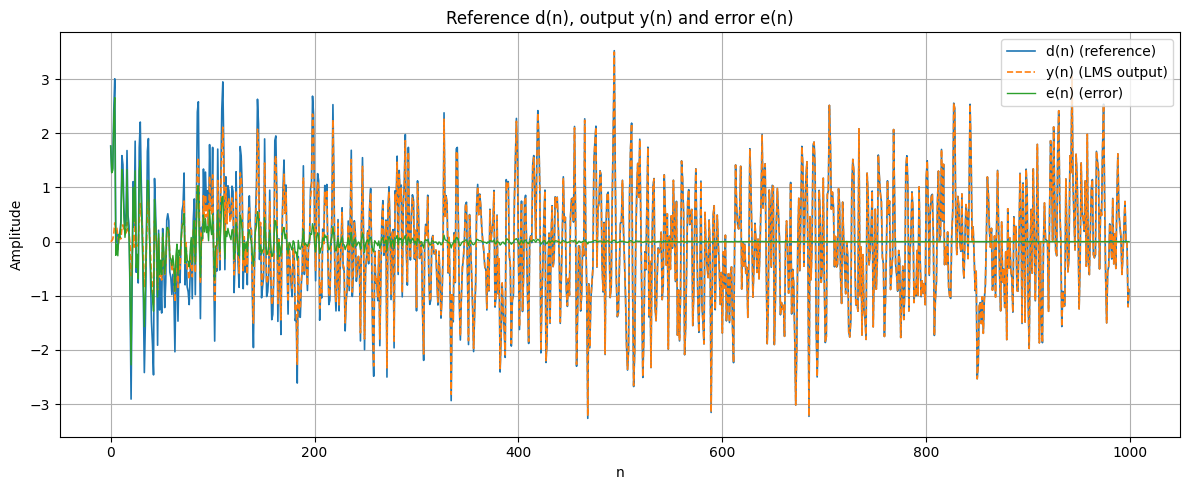

In [13]:

n = np.arange(len(d))

plt.figure(figsize=(12, 5))
plt.plot(n, d, label="d(n) (reference)", linewidth=1.2)
plt.plot(n, y, '--', label="y(n) (LMS output)", linewidth=1.2)
plt.plot(n, e, label="e(n) (error)", linewidth=1.0)
plt.title("Reference d(n), output y(n) and error e(n)")
plt.xlabel("n")
plt.ylabel("Amplitude")
plt.legend(loc="upper right")
plt.grid(True)
plt.tight_layout()
plt.show()

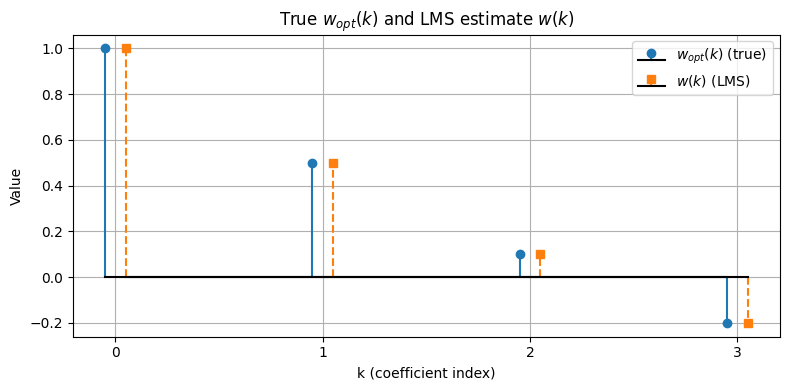

In [22]:


w_opt = np.array([1, 0.5, 0.1, -0.2])
w_est = W[-1]

k = np.arange(len(w_est))

plt.figure(figsize=(8, 4))
plt.stem(k - 0.05, w_opt, linefmt='C0-', markerfmt='C0o', basefmt='k-', label=r"$w_{opt}(k)$ (true)")
plt.stem(k + 0.05, w_est, linefmt='C1--', markerfmt='C1s', basefmt='k-', label=r"$w(k)$ (LMS)")
plt.title("True $w_{opt}(k)$ and LMS estimate $w(k)$")
plt.xlabel("k (coefficient index)")
plt.ylabel("Value")
plt.xticks(k)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [42]:
# Parameters
fc = 0.5
orders = [5, 10, 20]
steps = [0.01, 0.1, 0.5]

In [43]:
def run(P, mu):
    h = firwin(P + 1, fc)
    d = lfilter(h, [1], x)
    return algoLMS(x, d, P + 1, mu), d, h


In [48]:
def plot_case(ax, d, y, e, title):
    n = np.arange(len(d))
    ax.plot(n, d, label="d(n)")
    ax.plot(n, y, '--', label="y(n)")
    ax.plot(n, e, label="e(n)")
    ax.set_title(title)
    ax.set_xlabel("n")
    ax.set_ylim(-5, 5)
    ax.grid(True)
    ax.legend(loc="upper right")

In [49]:
def conv_time(e, thr=0.05):
    above = np.where(np.abs(e) > thr)[0]
    return above[-1] + 1 if len(above) else 0

P = 5, mu = 0.01, convergence time ≈ 337 samples
P = 10, mu = 0.01, convergence time ≈ 330 samples
P = 20, mu = 0.01, convergence time ≈ 438 samples


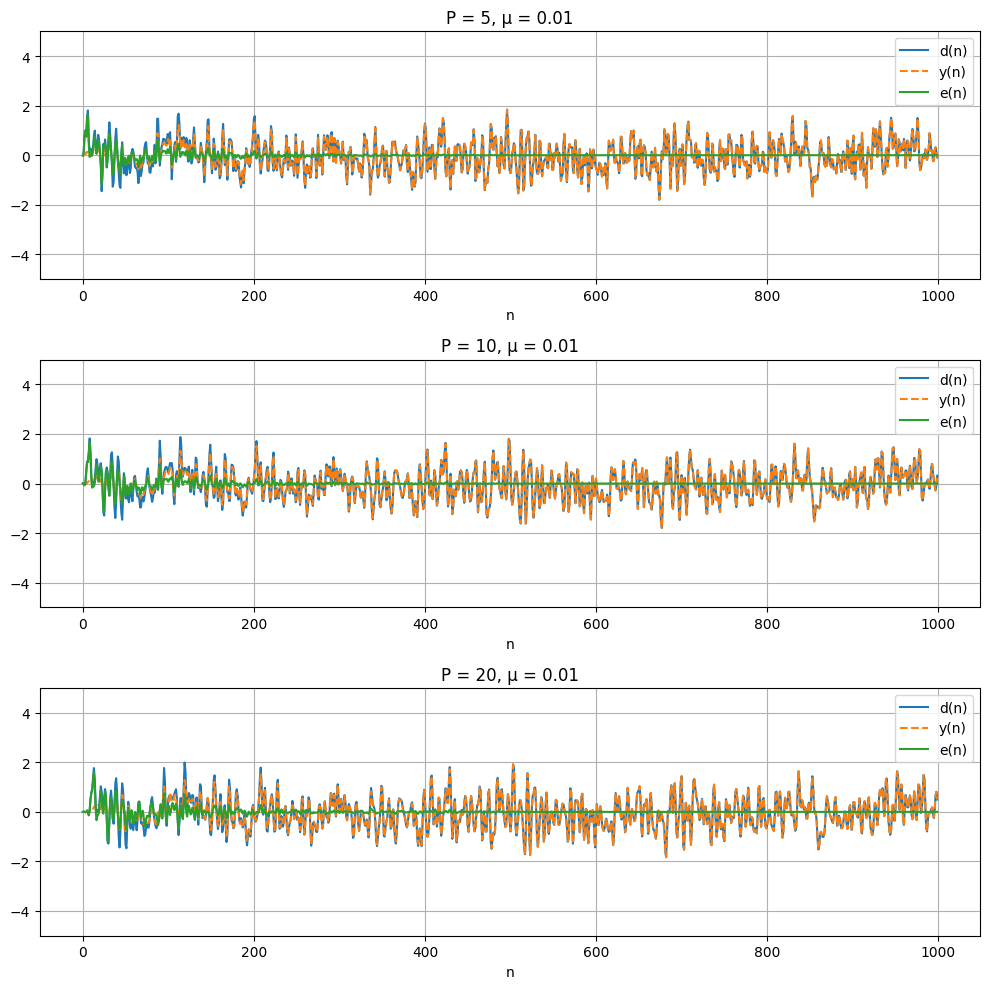

In [52]:
#impact of p
mu = 0.01
fig, ax = plt.subplots(3, 1, figsize=(10, 10))
for i, P in enumerate(orders):
    (W, y, e), d, h = run(P, mu)
    print(f"P = {P}, mu = {mu}, convergence time ≈ {conv_time(e)} samples")
    plot_case(ax[i], d, y, e, f"P = {P}, µ = {mu}")
plt.tight_layout()
plt.show()

P = 10, mu = 0.01, convergence time ≈ 330 samples
P = 10, mu = 0.1, convergence time ≈ 63 samples
P = 10, mu = 0.5, convergence time ≈ 1000 samples


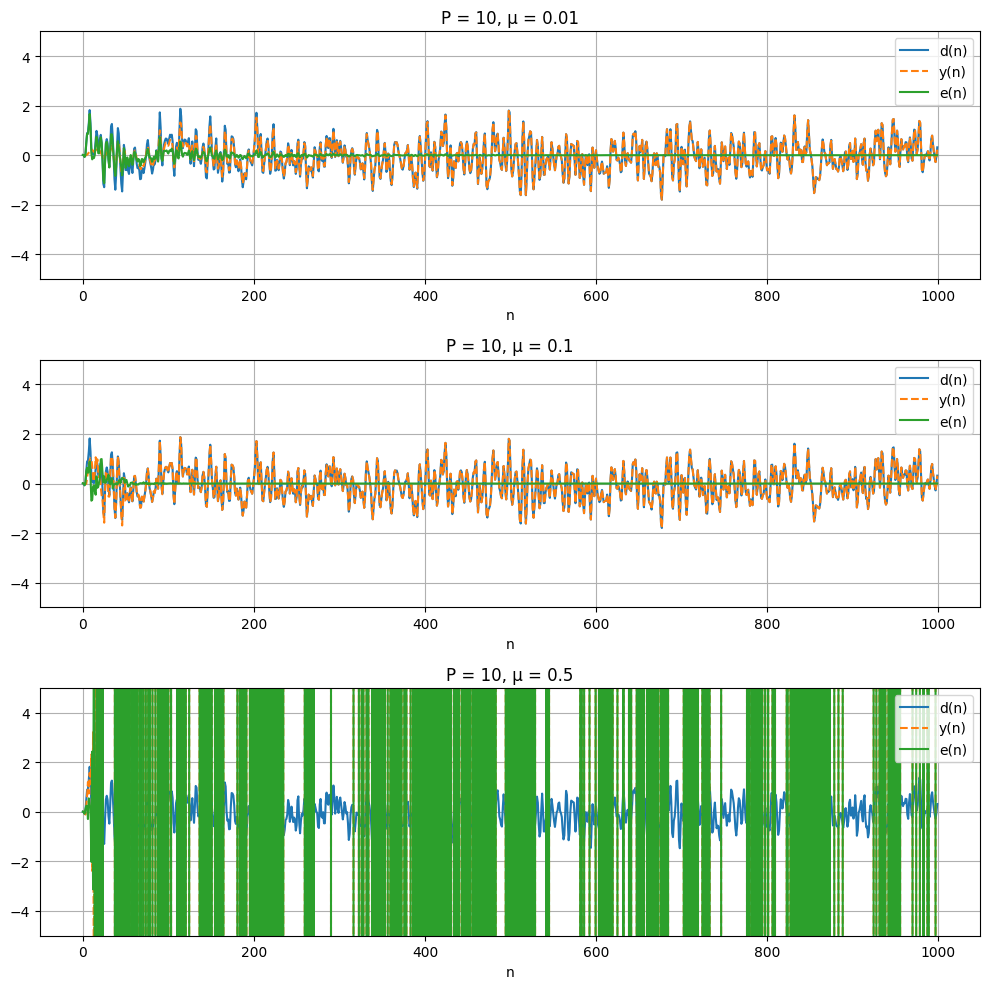

In [51]:
# Impact of mu
P = 10
fig, ax = plt.subplots(3, 1, figsize=(10, 10))
with np.errstate(all='ignore'):
    for i, mu in enumerate(steps):
        (W, y, e), d, h = run(P, mu)
        print(f"P = {P}, mu = {mu}, convergence time ≈ {conv_time(e)} samples")
        plot_case(ax[i], d, y, e, f"P = {P}, µ = {mu}")
plt.tight_layout()
plt.show()

In [56]:
signal, Fs = librosa.load("Voix1.wav", sr=None)

In [57]:
print(f"Sampling Rate: {Fs} Hz")
print(f"Duration: {len(signal) / Fs:.2f} seconds")
print(f"Signal Shape: {signal.shape}")

Sampling Rate: 16000 Hz
Duration: 5.31 seconds
Signal Shape: (85000,)


In [58]:
ipd.Audio(signal, rate=Fs)

In [60]:
mat = sio.loadmat("Rep.dat")
print(mat.keys())

dict_keys(['__header__', '__version__', '__globals__', 'RI'])


In [61]:
h_room = mat["RI"].squeeze()

print("Length of h_room:", len(h_room))

echo = fftconvolve(signal, h_room)[:len(signal)]

ipd.Audio(echo, rate=Fs)

Length of h_room: 2048


In [63]:
np.random.seed(0)
sigma = 0.01
d_noisy = echo + sigma * np.random.randn(len(echo))
ipd.Audio(d_noisy, rate=Fs)

In [64]:
M = len(h_room)


sigma2_x = np.mean(signal**2)
mu_max = 2 / (M * sigma2_x)
mu = 0.1 * mu_max

print(f"M = {M}, power of x = {sigma2_x:.5f}")
print(f"mu_max = {mu_max:.4f}, mu used = {mu:.4f}")

M = 2048, power of x = 0.02300
mu_max = 0.0425, mu used = 0.0042


In [67]:
W, y, e = algoLMS(signal, d_noisy, M, mu)
w_est = W[-1]

In [70]:
print("Microphone signal (echo + noise):")
display(ipd.Audio(d_noisy, rate=Fs))

print("After echo cancellation, e(n):")
display(ipd.Audio(e, rate=Fs))

Microphone signal (echo + noise):


After echo cancellation, e(n):


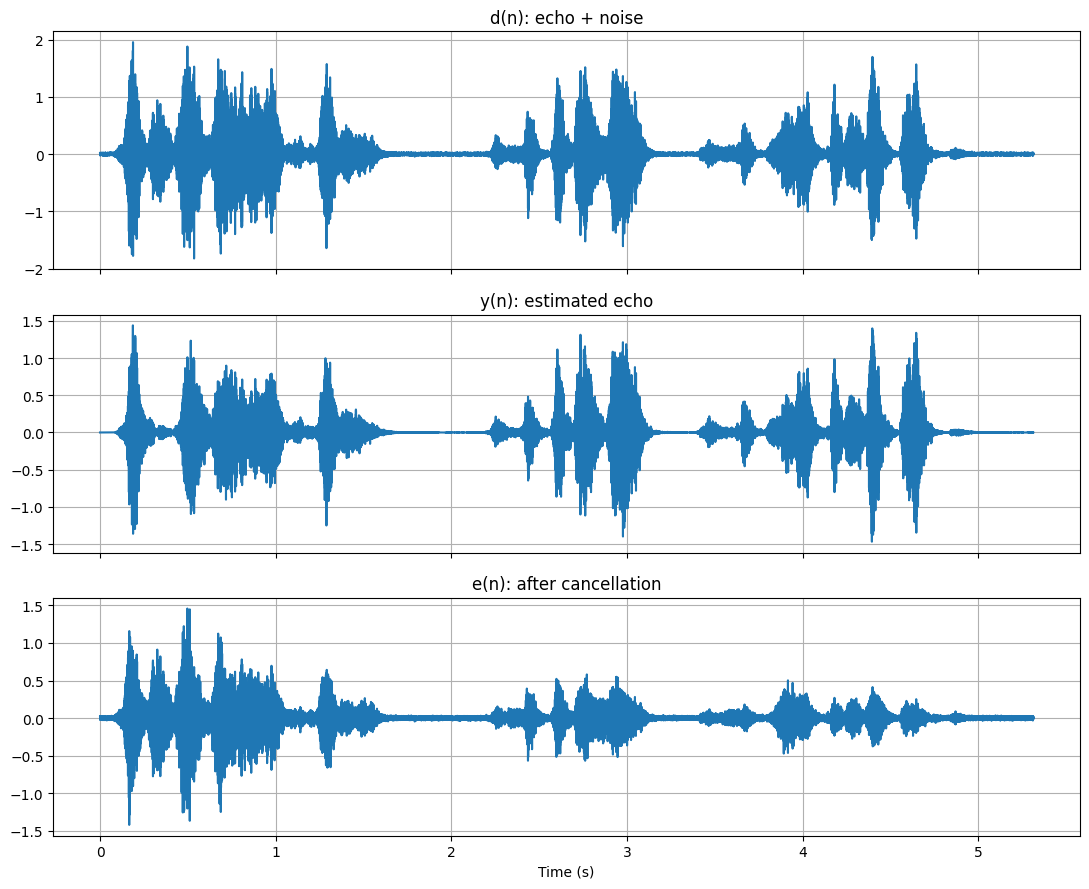

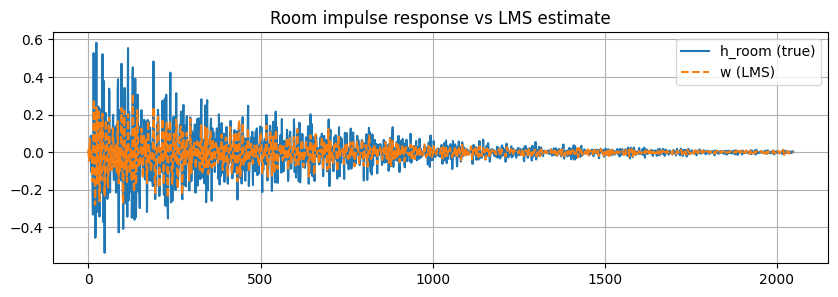

In [71]:

t = np.arange(len(signal)) / Fs

fig, ax = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
ax[0].plot(t, d_noisy); ax[0].set_title("d(n): echo + noise")
ax[1].plot(t, y);       ax[1].set_title("y(n): estimated echo")
ax[2].plot(t, e);       ax[2].set_title("e(n): after cancellation")
ax[2].set_xlabel("Time (s)")
for a in ax: a.grid(True)
plt.tight_layout(); plt.show()

# Estimated filter vs true room response
plt.figure(figsize=(10, 3))
plt.plot(h_room, label="h_room (true)")
plt.plot(w_est, '--', label="w (LMS)")
plt.legend(); plt.grid(True); plt.title("Room impulse response vs LMS estimate")
plt.show()

In [142]:
#parameters
L=len(h_room)
orders = [L//2, L, 2*L]
steps = [0.1, 0.3, 0.5]


In [164]:
x = signal
d = d_noisy
sigma2_x = np.mean(x**2)
mu_max = 2 / (L * sigma2_x)
ylim = 1.5 * np.max(np.abs(d))

In [165]:
def run(M, mu):
    W, y, e = algoLMS(x, d, M, mu)
    w= W[-1]
    return (w, y, e), d
ylim = 1.5 * np.max(np.abs(d))
thr = 0.1 * np.std(d)

In [166]:
def conv_time(e, thr):
    above = np.where(np.abs(e) > thr)[0]
    return above[-1] + 1 if len(above) else 0

def status(e, thr):
    if not np.all(np.isfinite(e)) or np.max(np.abs(e)) > 10:
      return "diverged"
    return "converged" if conv_time(e, thr) < len(e) - 1000 else "not converged"

In [167]:
def plot_case(ax, d, y, e, title, ylim=None):
    n = np.arange(len(d))
    ax.plot(n, d, label="d(n)")
    ax.plot(n, y, '--', label="y(n)")
    ax.plot(n, e, label="e(n)")
    ax.set_title(title)
    ax.set_xlabel("n")
    if ylim is not None:
        ax.set_ylim(-ylim, ylim)
    ax.grid(True)
    ax.legend(loc="upper right")

mu = 0.00212
M = 1024, mu = 0.00212, status ≈ not converged
M = 2048, mu = 0.00212, status ≈ not converged
M = 4096, mu = 0.00212, status ≈ not converged


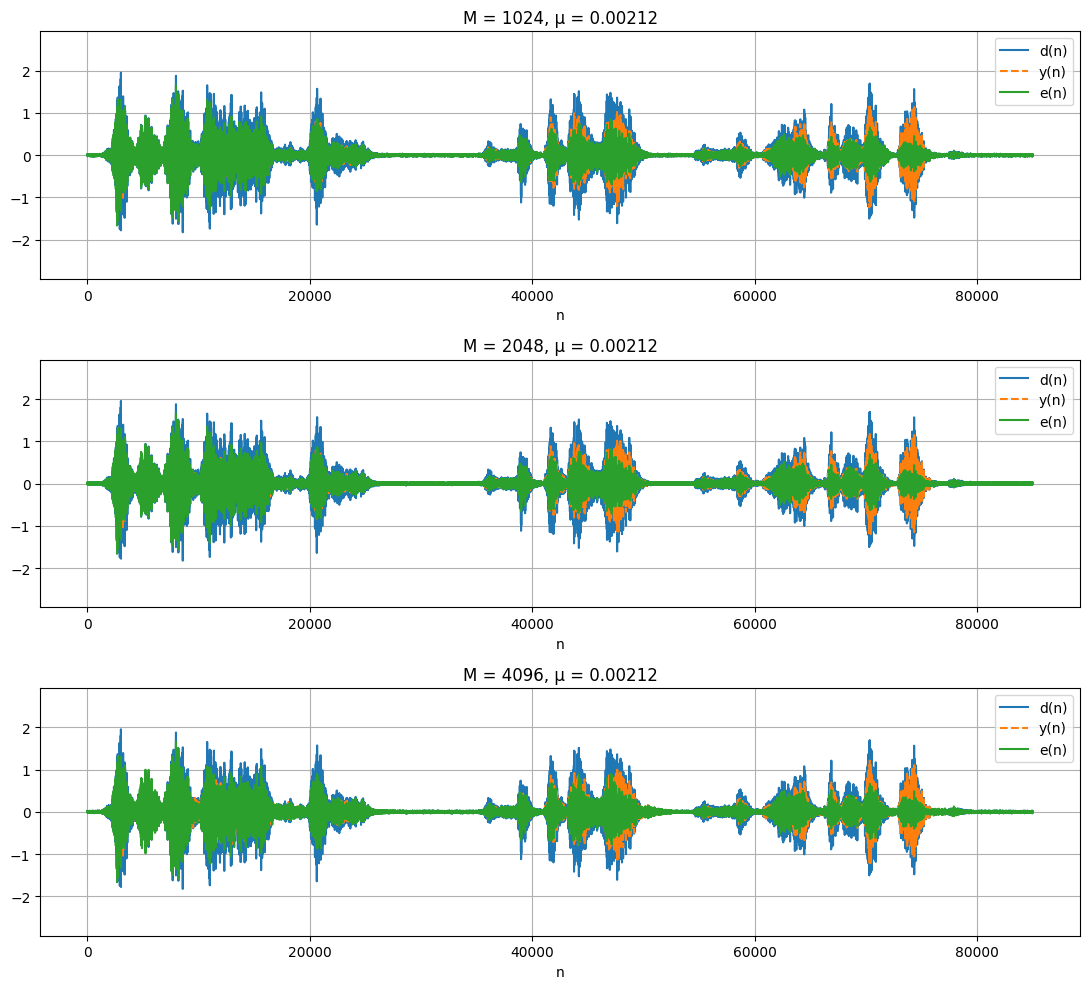

In [168]:
mu = 0.1 * 2 / (max(orders) * sigma2_x)
print(f"mu = {mu:.5f}")

fig, ax = plt.subplots(3, 1, figsize=(11, 10))
with np.errstate(all='ignore'):
    for i, M in enumerate(orders):
        (w, y, e), d_ = run(M, mu)
        plot_case(ax[i], d_, y, e, f"M = {M}, µ = {mu:.5f}", ylim)
        print(f"M = {M}, mu = {mu:.5f}, status ≈ {status(e, thr)}")
plt.tight_layout(); plt.show()

M = 2048, mu = 0.1·mu_max, status ≈ not converged
M = 2048, mu = 0.3·mu_max, status ≈ diverged
M = 2048, mu = 0.5·mu_max, status ≈ diverged


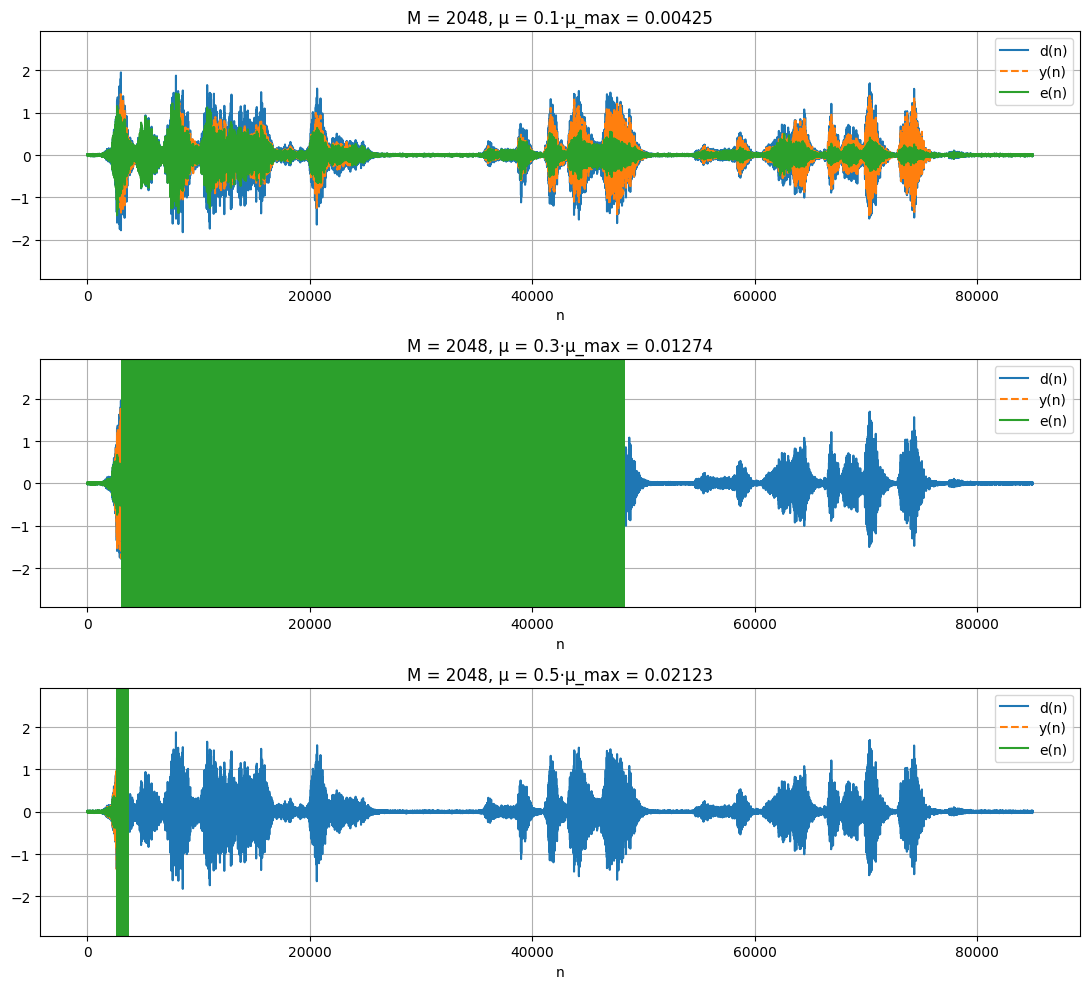

In [169]:
fig, ax = plt.subplots(3, 1, figsize=(11, 10))
M = L
with np.errstate(all='ignore'):
    for i, frac in enumerate(steps):
        mu = frac * mu_max
        (w, y, e), d_ = run(M, mu)
        plot_case(ax[i], d_, y, e, f"M = {M}, µ = {frac}·µ_max = {mu:.5f}", ylim)
        print(f"M = {M}, mu = {frac}·mu_max, status ≈ {status(e, thr)}")
plt.tight_layout(); plt.show()

In [174]:

mat_far = sio.loadmat("farspeech.mat")
mat_near = sio.loadmat("nearspeech.mat")

print([k for k in mat_far if not k.startswith("__")])
print([k for k in mat_near if not k.startswith("__")])

['x', 'fs']
['fs', 'v']


In [181]:

x = mat_far["x"].squeeze().astype(float)
v = mat_near["v"].squeeze().astype(float)

print("x:", x.shape, "| v:", v.shape)
print("max |x| =", np.max(np.abs(x)), "| max |v| =", np.max(np.abs(v)))

print(mat_far["fs"])
print(mat_near["fs"])

x: (268000,) | v: (268000,)
max |x| = 0.254547119140625 | max |v| = 1.16485595703125
[[8000]]
[[8000]]


In [182]:
Fs=8000
print("Far-end speech x(n):")
display(ipd.Audio(x, rate=Fs))

print("Near-end speech v(n):")
display(ipd.Audio(v, rate=Fs))

Far-end speech x(n):


Near-end speech v(n):


In [183]:
mat = sio.loadmat("Rep.dat")
print([k for k in mat if not k.startswith("__")])

h_room = mat["RI"].squeeze().astype(float)
print("Length of h_room:", len(h_room))

echo = fftconvolve(x, h_room)[:len(x)]

print("Echo:")
display(ipd.Audio(echo, rate=Fs))

['RI']
Length of h_room: 2048
Echo:


In [184]:
N = min(len(x), len(v), len(echo))
x = x[:N]
v = v[:N]
echo = echo[:N]

d = echo + v

print("Echo only:")
display(ipd.Audio(echo, rate=Fs))

print("Near-end speech v(n):")
display(ipd.Audio(v, rate=Fs))

print("Dialogue d(n) = echo + v(n):")
display(ipd.Audio(d, rate=Fs))

Echo only:


Near-end speech v(n):


Dialogue d(n) = echo + v(n):


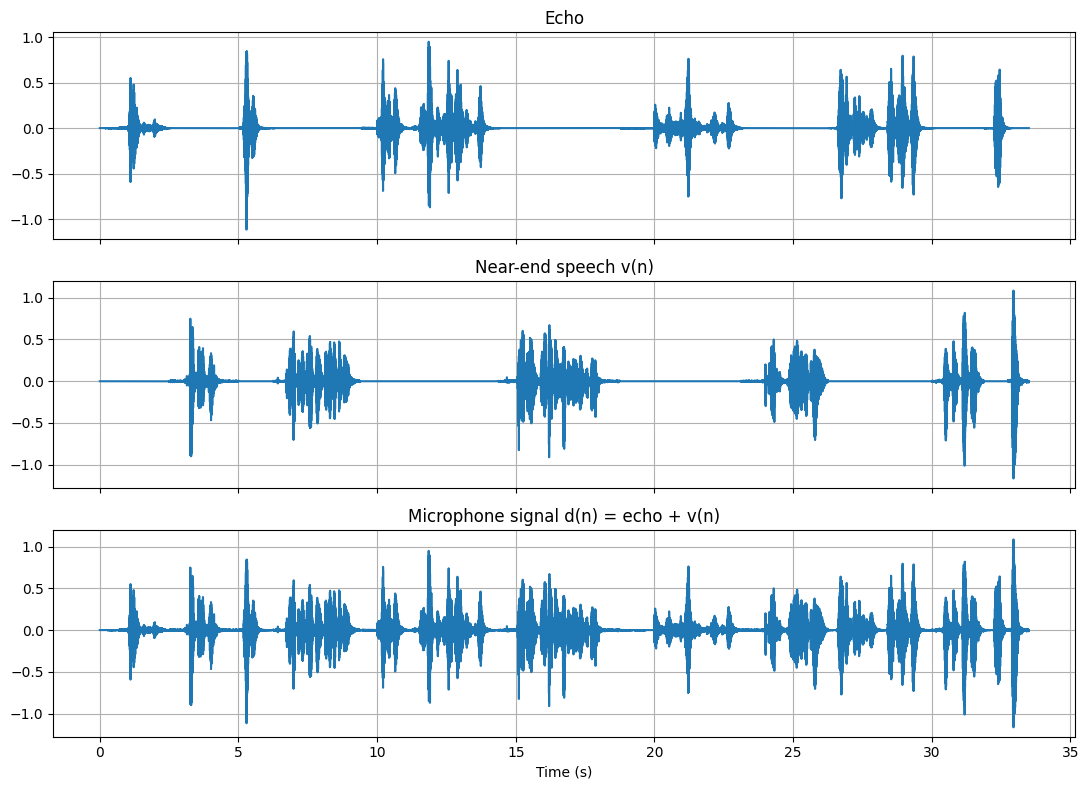

In [185]:
t = np.arange(N) / Fs
fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
ax[0].plot(t, echo); ax[0].set_title("Echo")
ax[1].plot(t, v);    ax[1].set_title("Near-end speech v(n)")
ax[2].plot(t, d);    ax[2].set_title("Microphone signal d(n) = echo + v(n)")
ax[2].set_xlabel("Time (s)")
for a in ax: a.grid(True)
plt.tight_layout(); plt.show()

In [186]:
M = len(h_room)
sigma2_x = np.mean(x**2)
mu_max = 2 / (M * sigma2_x)
mu = 0.05 * mu_max
print(f"M = {M}, mu_max = {mu_max:.5f}, mu = {mu:.5f}")

M = 2048, mu_max = 3.45499, mu = 0.17275


In [194]:
W, y, e = algoLMS(x, d, M, mu)
w_est=W[-1]
print("Diverged?", not np.all(np.isfinite(e)) or np.max(np.abs(e)) > 10 * np.max(np.abs(d)))

Diverged? False


In [195]:
print("Microphone signal d(n) = echo + v(n):")
display(ipd.Audio(d, rate=Fs))

print("After cancellation e(n):")
display(ipd.Audio(e, rate=Fs))

print("Near-end speech v(n) (reference):")
display(ipd.Audio(v, rate=Fs))

Microphone signal d(n) = echo + v(n):


After cancellation e(n):


Near-end speech v(n) (reference):


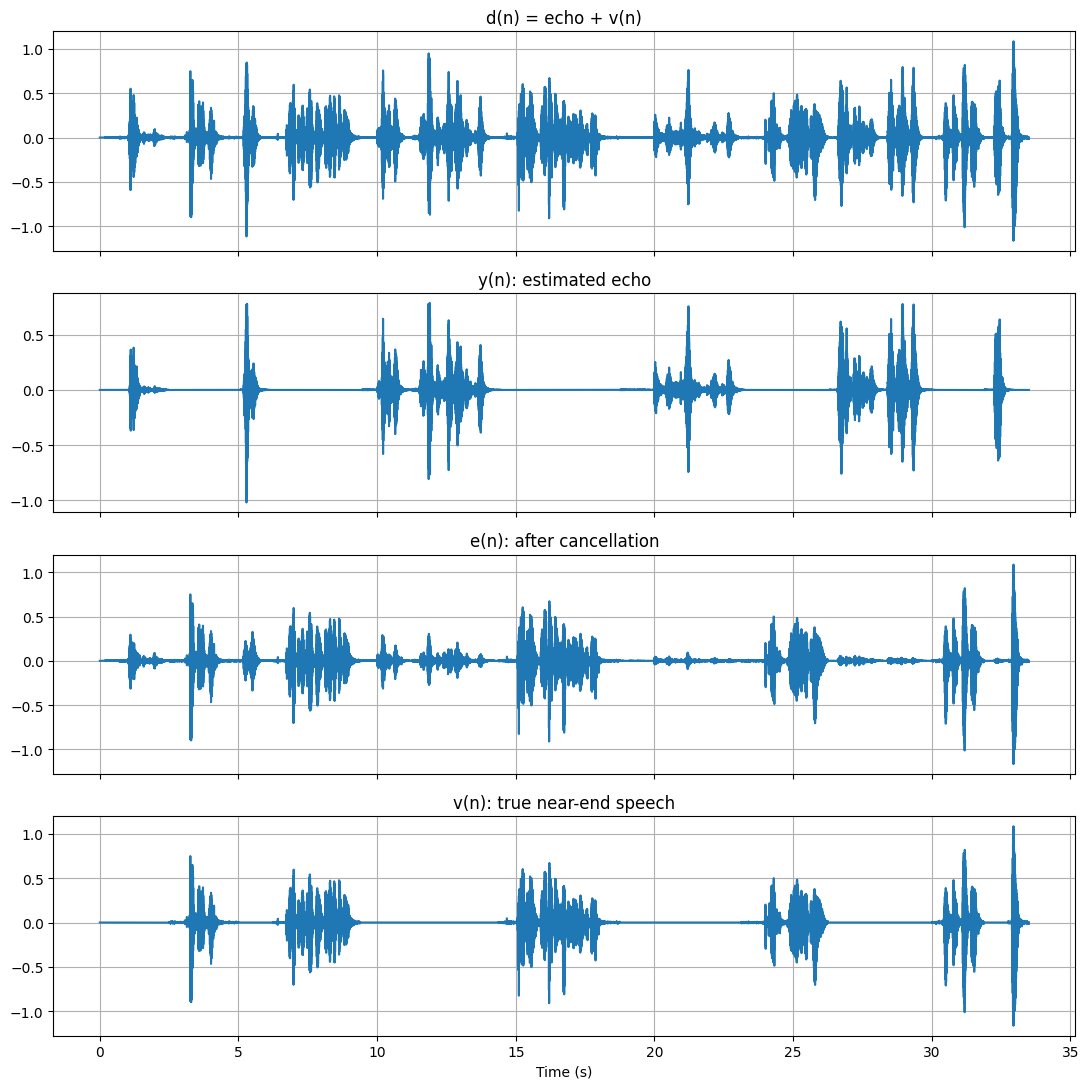

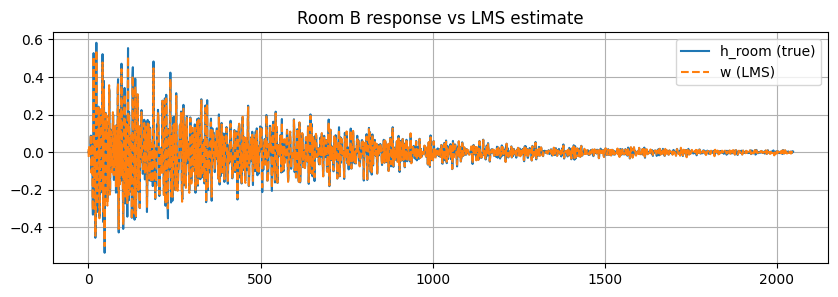

In [196]:
t = np.arange(len(d)) / Fs
fig, ax = plt.subplots(4, 1, figsize=(11, 11), sharex=True)
ax[0].plot(t, d);    ax[0].set_title("d(n) = echo + v(n)")
ax[1].plot(t, y);    ax[1].set_title("y(n): estimated echo")
ax[2].plot(t, e);    ax[2].set_title("e(n): after cancellation")
ax[3].plot(t, v);    ax[3].set_title("v(n): true near-end speech")
ax[3].set_xlabel("Time (s)")
for a in ax: a.grid(True)
plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 3))
plt.plot(h_room, label="h_room (true)")
plt.plot(w_est, '--', label="w (LMS)")
plt.legend(); plt.grid(True); plt.title("Room B response vs LMS estimate")
plt.show()